# Spectral diagnostics for the quantum layer

Two read-only diagnostics for `MerlinTunableSimple`'s quantum layer (`W1 -> angle encoding -> W2`,
currently restricted to `n_encoding_layers=1` — see `src/spectral.py`'s module docstring):

1. **`omega_eff`** (spectral second moment) — how much high-frequency content the quantum layer
   supplies per encoded feature, via an FFT sweep of that feature's phase with everything else held fixed.
2. **`eta_lambda`** (Haar-relative harmonic weight) — whether the state `W1` prepares (before any
   encoding) concentrates or depletes amplitude in each "lambda-photons-in-mode-k" sector relative
   to a Haar-random `U(m)`.

Both are implemented in `src/spectral.py` and validated by real assertions (not smoke tests) in
`tests/test_spectral.py`: band-limit exactness, Haar calibration, the `n=1`/`m=2` degenerate case,
identity-`W2` collapse, and normalisation invariance.

## 0 - Setup

In [38]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models   import MerlinTunableSimple
from src.pde      import HeatEquation, WaveEquation
from src.loss     import total_loss
from src.train    import train
from src.sampler  import DataSampler
from src.spectral import spectral_second_moment, haar_relative_harmonic_weight
from src.plotter  import plot_omega_eff_trajectory, plot_eta_lambda_comparison

# Prefer CUDA, then Apple Silicon GPU (MPS), then fall back to CPU.
if torch.cuda.is_available():
    device = torch.device('cuda')
# elif torch.backends.mps.is_available():
#     device = torch.device('mps')
else:
    device = torch.device('cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu  |  dtype: torch.float32


## 1 - Config

In [41]:
SEED = 42
EPOCHS = 1000
DIAG_EVERY = 100   # periodic diagnostic cadence (prompt's suggested default)
B_REF = 64         # reference (x, t) points for omega_eff's held-fixed configuration (prompt's default)

pde = HeatEquation(freq=1.5)
# pde = WaveEquation()

n_encoding_layers = 1  # REQUIRED: spectral.py currently only supports the single W1 -> encode -> W2 circuit
feature_size = 4

sampler = DataSampler(pde=pde, device=device, dtype=dtype)

## 2 - Validate `src/spectral.py`

Runs the real test suite (`tests/test_spectral.py`) before trusting any numbers below:
band-limit exactness (the FFT sweep is a degree-`n_photons` trig polynomial, checked by
comparing critical-rate vs. 2x-oversampled sweeps), Haar calibration (`eta_lambda` averages to
1.0 over `R=200` Haar-random substitutes for `W1`), the `n=1`/`m=2` degenerate case, identity-`W2`
collapse (`omega_eff` must be `nan` when there's no mixing after encoding — a real physical
property, not a bug), and normalisation invariance.

In [42]:
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/test_spectral.py", "-v"],
    cwd=os.path.abspath(".."), capture_output=True, text=True,
)
print(result.stdout[-2000:])
if result.returncode != 0:
    print(result.stderr[-2000:])
assert result.returncode == 0, "spectral diagnostics tests failed — do not trust results below"

n 3.13.12, pytest-9.1.1, pluggy-1.6.0 -- /Users/timoj/Documents/EPFL_local/MA4/eth_hackathon/QPINN-Analysis/.venv/bin/python
cachedir: .pytest_cache
rootdir: /Users/timoj/Documents/EPFL_local/MA4/eth_hackathon/QPINN-Analysis
collecting ... collected 8 items

tests/test_spectral.py::test_band_limit_exactness PASSED                 [ 12%]
tests/test_spectral.py::test_haar_calibration PASSED                     [ 25%]
tests/test_spectral.py::test_single_photon_degenerate_case PASSED        [ 37%]
tests/test_spectral.py::test_identity_w2_collapse PASSED                 [ 50%]
tests/test_spectral.py::test_normalization_invariance PASSED             [ 62%]
tests/test_spectral.py::test_mode_permutation_gauge_symmetry PASSED      [ 75%]
tests/test_spectral.py::test_gauge_invariant_summary_is_sorted PASSED    [ 87%]
tests/test_spectral.py::test_feature_map_jacobian_matches_finite_differences PASSED [100%]

=============================== warnings summary ===============================
tests/te

## 3 - Train with periodic diagnostics

The original spec asked for a `--diagnostics` CLI flag evaluating both metrics at
initialization, every `N` epochs, and at the end — this repo has no CLI training entrypoint or
logging framework (every run here is a notebook calling `train()` directly with `print()`
progress), so this adapts that to the same pattern: `train()`'s existing `eval_callback` hook
(already used for entropy/rel-L2 tracking in `EntanglementEntropy.ipynb`) drives the periodic
`omega_eff` evaluation, plus explicit before/after snapshots to guarantee "at init" and "at the
end" regardless of whether `EPOCHS` divides evenly by `DIAG_EVERY`.

`omega_eff` is tracked across the full trajectory (one value per feature per checkpoint) since
it's a single-scalar-per-feature summary; `eta_lambda` is only captured at init and at the end
(it's already an array over `lambda`, so a full epoch trajectory would be an array-of-arrays —
the comparison that's actually useful is "did training reshape it", i.e. two snapshots).

In [43]:
torch.manual_seed(SEED)
model = MerlinTunableSimple(feature_size=feature_size, n_encoding_layers=n_encoding_layers).to(device)

reference_xt = sampler.sample_interior(B_REF).detach()  # fixed reference batch for the whole run


def snapshot_omega_eff(m):
    return {k: spectral_second_moment(m, reference_xt, feature_index=k).omega_eff for k in range(m.feature_size)}


def snapshot_eta_lambda(m):
    return {k: haar_relative_harmonic_weight(m, mode_k=k).eta_lambda for k in range(m.feature_size)}


# --- at initialization ---
epochs_recorded = [0]
omega_eff_trajectory = {k: [v] for k, v in snapshot_omega_eff(model).items()}
eta_lambda_init = snapshot_eta_lambda(model)
print("omega_eff at init:", {k: round(v, 4) for k, v in snapshot_omega_eff(model).items()})


def eval_callback(m, epoch):
    epochs_recorded.append(epoch)
    for k, v in snapshot_omega_eff(m).items():
        omega_eff_trajectory[k].append(v)


train(
    model=model, pde=pde, loss_fn=total_loss,
    epochs=EPOCHS, log_every=DIAG_EVERY, seed=SEED,
    device=device, dtype=dtype,
    eval_every=DIAG_EVERY, eval_callback=eval_callback,
)

# --- at the end (guaranteed regardless of whether EPOCHS % DIAG_EVERY == 0) ---
if epochs_recorded[-1] != EPOCHS:
    epochs_recorded.append(EPOCHS)
    for k, v in snapshot_omega_eff(model).items():
        omega_eff_trajectory[k].append(v)

eta_lambda_final = snapshot_eta_lambda(model)
print("omega_eff at end:", {k: round(v, 4) for k, v in snapshot_omega_eff(model).items()})

omega_eff at init: {0: 0.4486, 1: 0.4776, 2: 0.5417, 3: 0.4419}
Parameters — total: 310  trainable: 310

Training for 1000 epochs on cpu  (dtype=torch.float32)
Epoch     1/1000 | Loss: 3.9304e+00 | PDE: 6.38e-06 | Cons: 1.64e-02 | IC: 3.92e-01 | BC: 4.89e-03 | Time: 0.2s
Epoch   100/1000 | Loss: 1.2595e+00 | PDE: 2.97e-01 | Cons: 5.08e+00 | IC: 4.09e-02 | BC: 4.51e-02 | Time: 14.6s
Epoch   200/1000 | Loss: 1.1278e+00 | PDE: 2.71e-01 | Cons: 4.89e+00 | IC: 3.26e-02 | BC: 4.21e-02 | Time: 29.2s
Epoch   300/1000 | Loss: 7.8710e-01 | PDE: 2.51e-01 | Cons: 1.95e+00 | IC: 2.83e-02 | BC: 5.81e-02 | Time: 43.5s
Epoch   400/1000 | Loss: 2.1827e-01 | PDE: 5.27e-02 | Cons: 1.24e+00 | IC: 2.93e-03 | BC: 1.23e-02 | Time: 57.4s
Epoch   500/1000 | Loss: 7.2204e-02 | PDE: 1.15e-02 | Cons: 3.65e-01 | IC: 1.78e-03 | BC: 6.42e-03 | Time: 71.3s
Epoch   600/1000 | Loss: 3.2001e-02 | PDE: 6.69e-03 | Cons: 1.36e-01 | IC: 8.76e-04 | BC: 2.91e-03 | Time: 85.7s
Epoch   700/1000 | Loss: 3.1547e-02 | PDE: 5.75e-0

## 4 - Plot

Saved: figures/spectral_diagnostics/omega_eff_vs_epoch.png


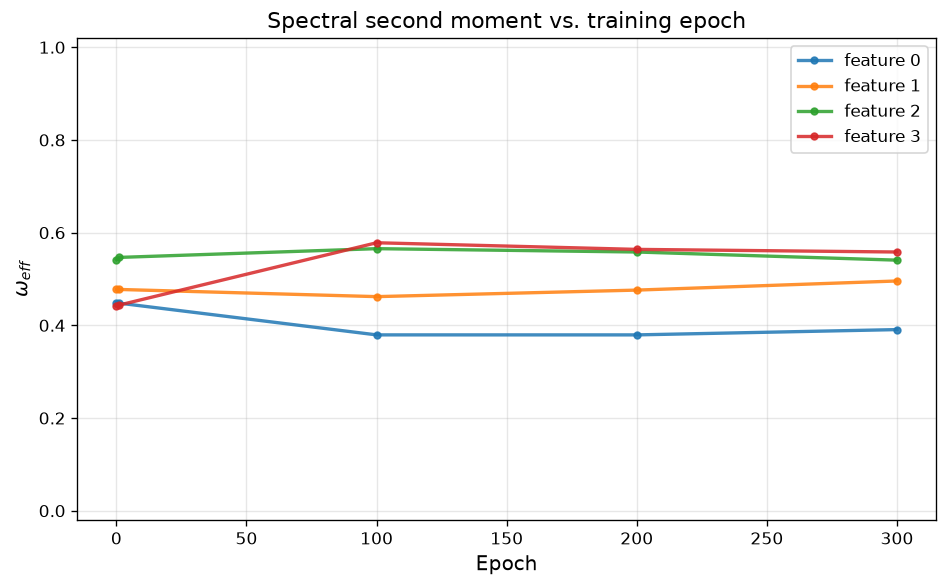

Saved: figures/spectral_diagnostics/eta_lambda_init_vs_final.png


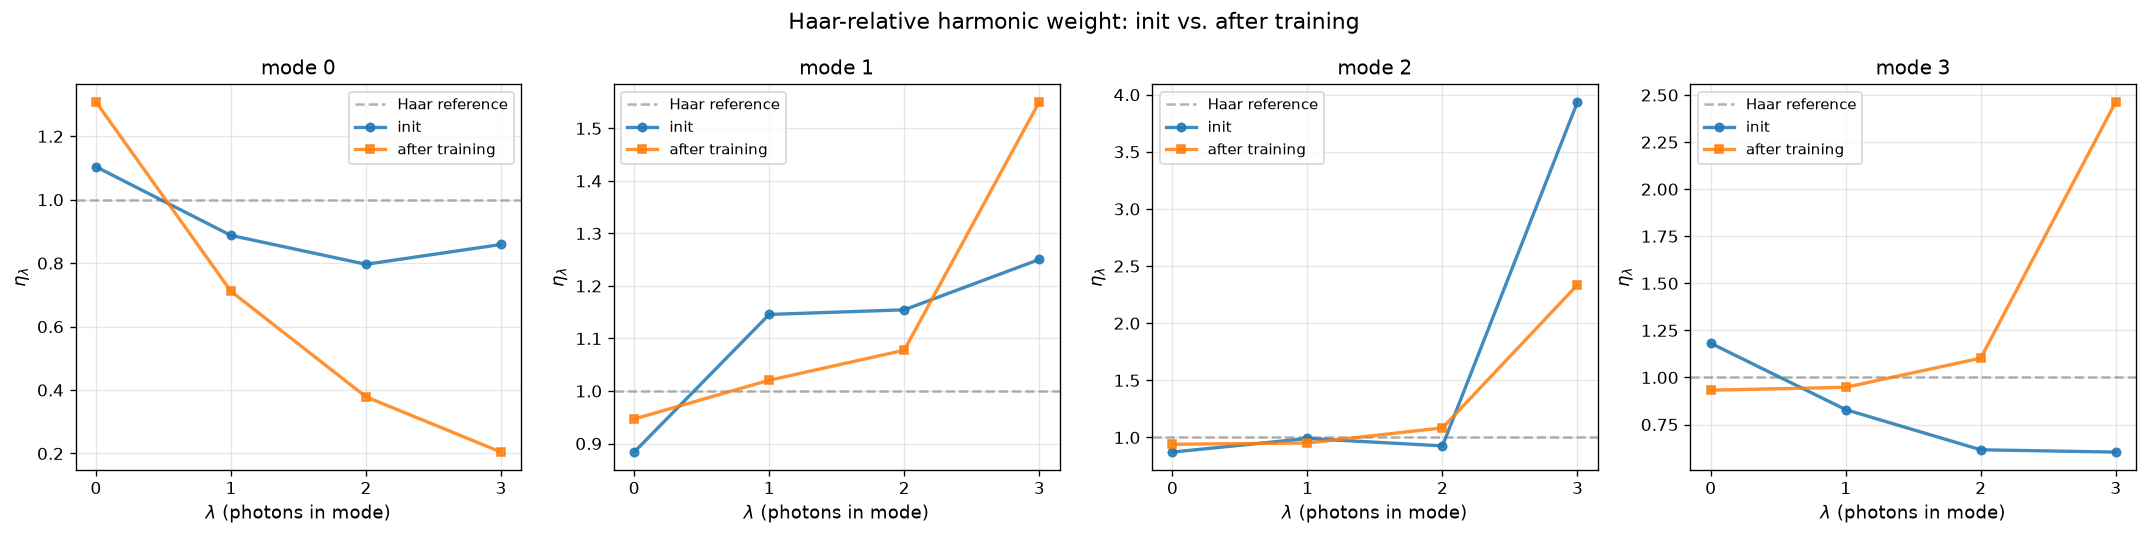

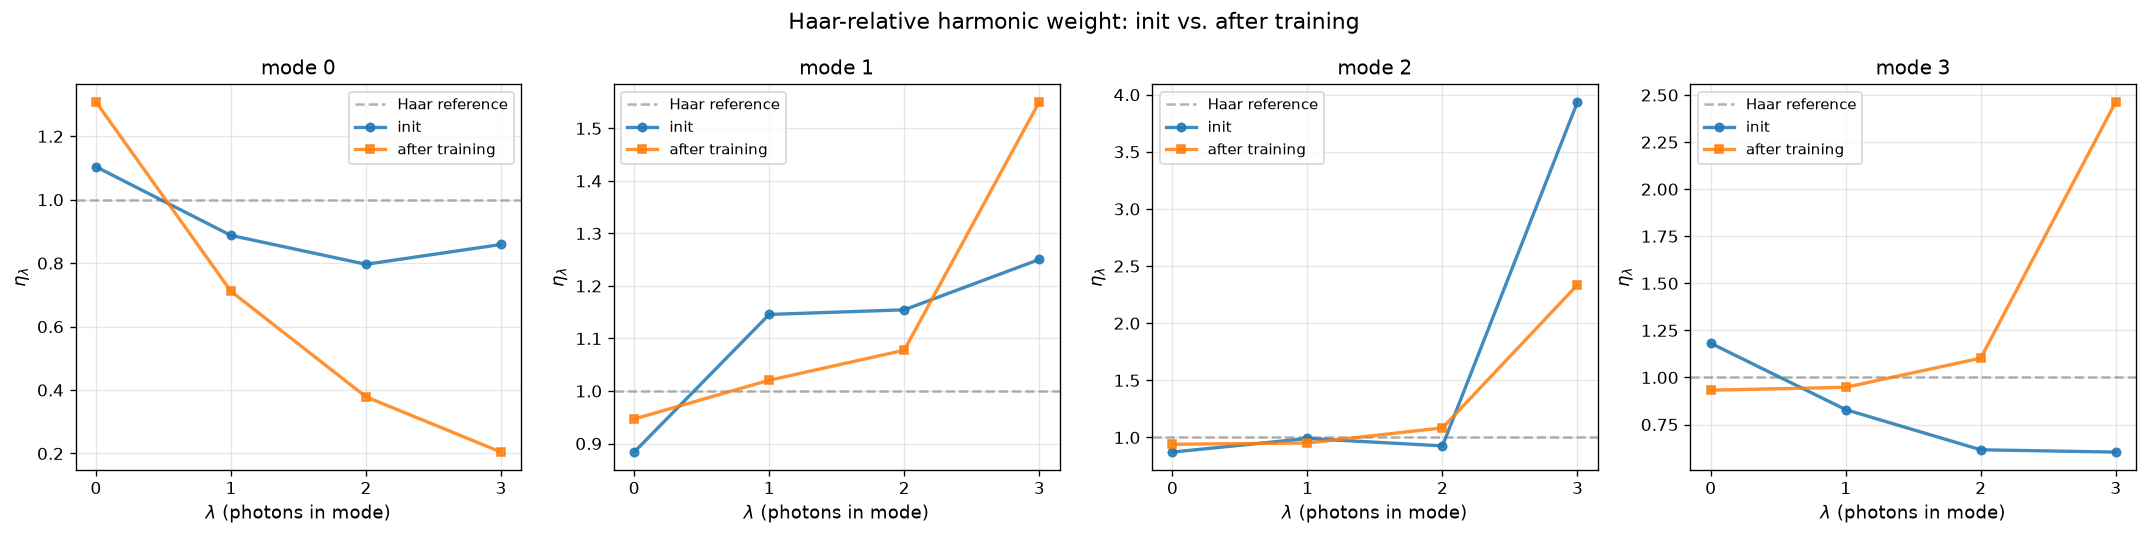

In [13]:
plot_omega_eff_trajectory(
    epochs_recorded, omega_eff_trajectory,
    save_path="figures/spectral_diagnostics/omega_eff_vs_epoch.png",
    show=True,
)

plot_eta_lambda_comparison(
    eta_lambda_init, eta_lambda_final,
    save_path="figures/spectral_diagnostics/eta_lambda_init_vs_final.png",
    show=True,
)

## 5 - Gauge-invariant summaries

Feature/mode index `k` is not a physical label: permuting modes while simultaneously
transforming `W1 -> P_sigma W1`, `W2 -> W2 P_sigma^dagger`, and permuting the corresponding rows
of `feature_map`'s output layer is an **exact** symmetry of the model — same function, same loss
(verified to float32 precision in `tests/test_spectral.py::test_mode_permutation_gauge_symmetry`,
independent of a separate finding that `LI_simple`'s 20 parameters are short of the 25 a literal
full-depth-Clements `U(5)` mesh would have — the symmetry holds regardless of that gap).

Both `omega_eff^{(k)}` and `w_lambda^{(k)}` transform the same way under this relabeling, so
"feature `k` has a low score" is a statement about *one trained instance*, not the architecture.
What's gauge-invariant is a symmetric function across `k`: the sorted profile, max, or mean.
`spectral.gauge_invariant_summary` computes both views in one call.

In [14]:
from src.spectral import gauge_invariant_summary

summary = gauge_invariant_summary(model, reference_xt)

print("omega_eff, labeled (native feature order):", summary.omega_eff_labeled.round(decimals=4).tolist())
print("omega_eff, sorted  (gauge-invariant)     :", summary.omega_eff_sorted.round(decimals=4).tolist())
print()
print("w_lambda max  (gauge-invariant), per lambda :", summary.w_lambda_max.round(decimals=4).tolist())
print("w_lambda mean (gauge-invariant), per lambda :", summary.w_lambda_mean.round(decimals=4).tolist())

omega_eff, labeled (native feature order): [0.39079999923706055, 0.49570000171661377, 0.5407000184059143, 0.5583000183105469]
omega_eff, sorted  (gauge-invariant)     : [0.5583000183105469, 0.5407000184059143, 0.49570000171661377, 0.39079999923706055]

w_lambda max  (gauge-invariant), per lambda : [0.7476999759674072, 0.29159998893737793, 0.12600000202655792, 0.07039999961853027]
w_lambda mean (gauge-invariant), per lambda : [0.5896999835968018, 0.25940001010894775, 0.10409999638795853, 0.046799998730421066]


## 6 - Seed-stability check

The honest test the review proposes: retrain across seeds, compute both the labeled `omega_eff`
vector and its sorted version. If the labeled ranking reshuffles across seeds while the sorted
profile stays put, the per-index reading is measuring initialization (which mode index the RNG
happened to route which frequency content to), not architecture.

Trains `STABILITY_SEEDS` fresh models (smaller epoch budget than section 3 — this is about the
*ranking*, which should stabilize well before full convergence, not about final accuracy).


Seed 1
Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 5.8831e+00 | PDE: 2.94e-07 | Cons: 8.32e-02 | IC: 5.72e-01 | BC: 1.56e-01 | Time: 0.1s
Epoch   300/300 | Loss: 1.3539e+00 | PDE: 2.25e-01 | Cons: 5.13e+00 | IC: 5.86e-02 | BC: 2.93e-02 | Time: 42.3s

Done — 42.3s total

Seed 2
Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 6.9560e+00 | PDE: 2.29e-05 | Cons: 2.70e-01 | IC: 6.31e-01 | BC: 6.22e-01 | Time: 0.1s
Epoch   300/300 | Loss: 5.0190e+00 | PDE: 4.50e-02 | Cons: 4.45e-02 | IC: 4.95e-01 | BC: 1.65e-02 | Time: 42.5s

Done — 42.5s total

Seed 3
Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 7.5567e+00 | PDE: 1.29e-07 | Cons: 1.39e-01 | IC: 7.32e-01 | BC: 2.26e-01 | Time: 0.1s
Epoch   300/300 | Loss: 1.0869e+00 | PDE: 3.94e-01 | Cons: 1.19e+00 | IC: 5.44e-02 | BC: 2.92e

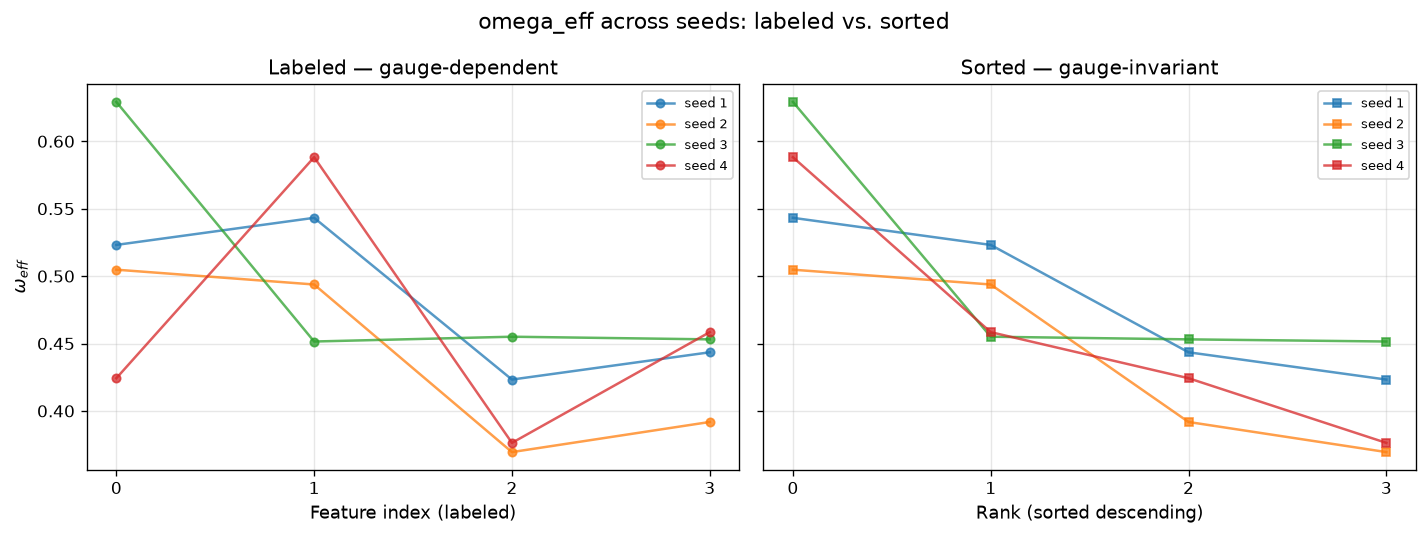

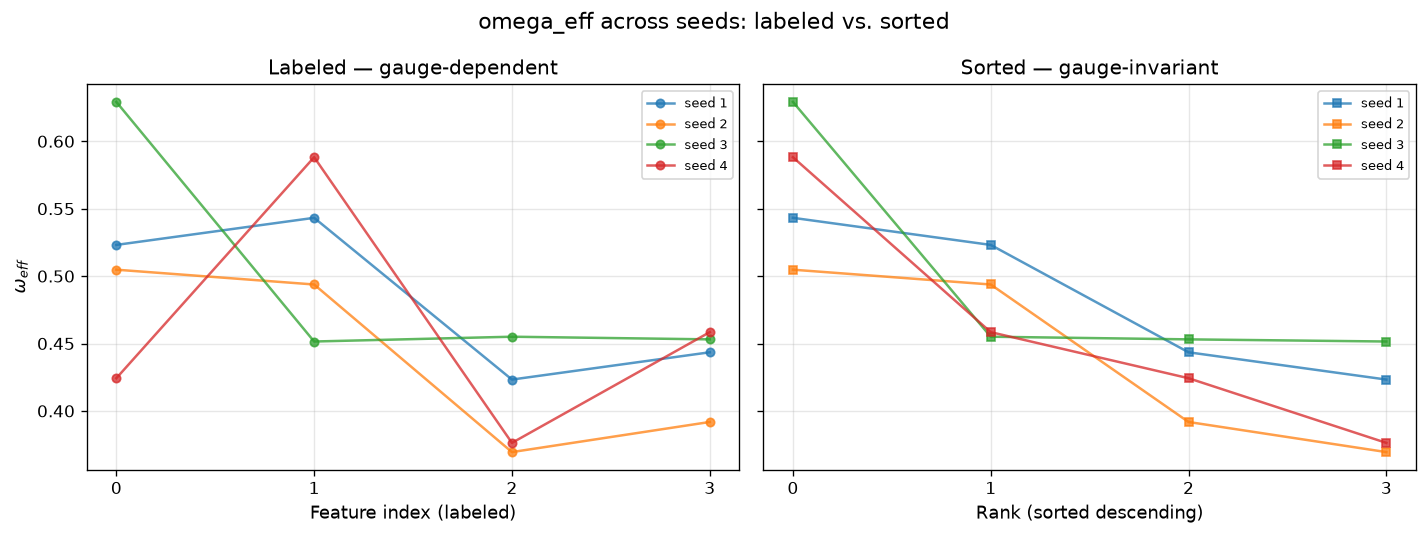

In [10]:
from src.spectral import all_features_omega_eff
from src.plotter import plot_gauge_stability

STABILITY_SEEDS = [1, 2, 3, 4]
STABILITY_EPOCHS = 300

omega_eff_labeled_by_seed = {}
omega_eff_sorted_by_seed = {}

for seed in STABILITY_SEEDS:
    print(f"\n{'='*60}\nSeed {seed}\n{'='*60}")
    torch.manual_seed(seed)
    m = MerlinTunableSimple(feature_size=feature_size, n_encoding_layers=n_encoding_layers).to(device)
    train(
        model=m, pde=pde, loss_fn=total_loss,
        epochs=STABILITY_EPOCHS, log_every=STABILITY_EPOCHS, seed=seed,
        device=device, dtype=dtype,
    )
    labeled = all_features_omega_eff(m, reference_xt)
    sorted_vals, _ = torch.sort(labeled, descending=True)
    omega_eff_labeled_by_seed[seed] = labeled
    omega_eff_sorted_by_seed[seed] = sorted_vals

plot_gauge_stability(
    omega_eff_labeled_by_seed, omega_eff_sorted_by_seed,
    save_path="figures/spectral_diagnostics/gauge_stability.png",
    show=True,
)

## 7 - Physical realized lattice

`omega_eff` and the accessible-frequency band `{-n_photons,...,n_photons}` are statements about
`theta`-space (the encoded phases), not `(x, t)` directly. Pushing forward through `feature_map`
(`Phi`), a `theta`-space harmonic `omega` on feature `k` contributes a **local** spatial frequency
`omega * d(Phi_k)/d(x,t)` to `u(x,t)` — not `omega` itself. Since `feature_map` has a `Tanh`
(nonlinear), this Jacobian varies across the domain, so each lattice point is a **chirp**, not a
fixed tone, in physical space (verified: `feature_map_jacobian` matches central finite differences
to `~2.5e-5`, see `tests/test_spectral.py`).

For each feature, picks its dominant non-DC `theta`-space frequency (from section 3/5's sweep) and
scatters `omega * J` over the reference batch — the spread within one feature's cluster *is* the
chirp; report the distribution, not a single number.

feature 0: dominant non-DC omega = +1  (S=0.0044)
feature 1: dominant non-DC omega = +1  (S=0.0042)
feature 2: dominant non-DC omega = +1  (S=0.0053)
feature 3: dominant non-DC omega = +1  (S=0.0066)
Saved: figures/spectral_diagnostics/physical_realized_frequency.png


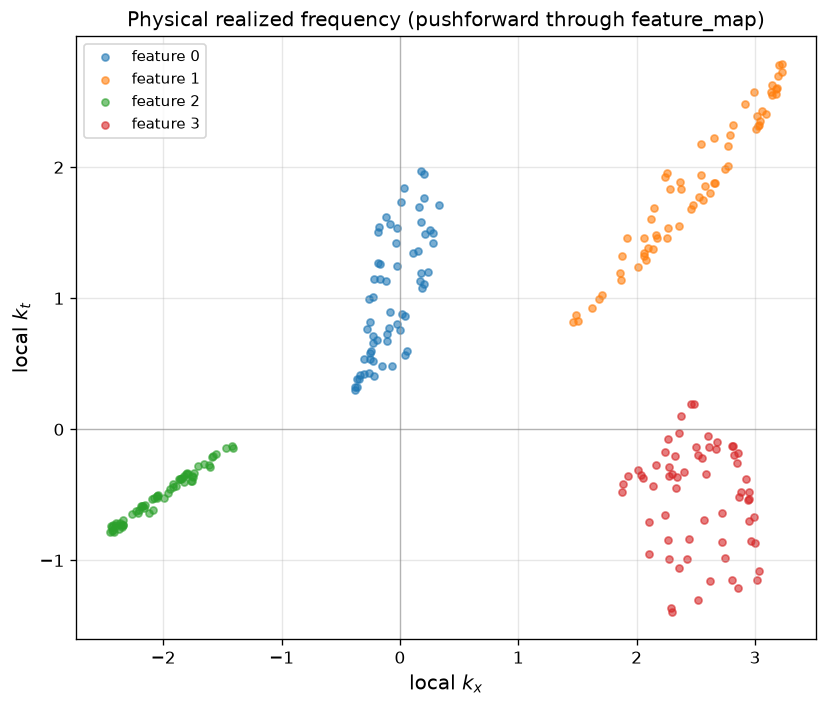

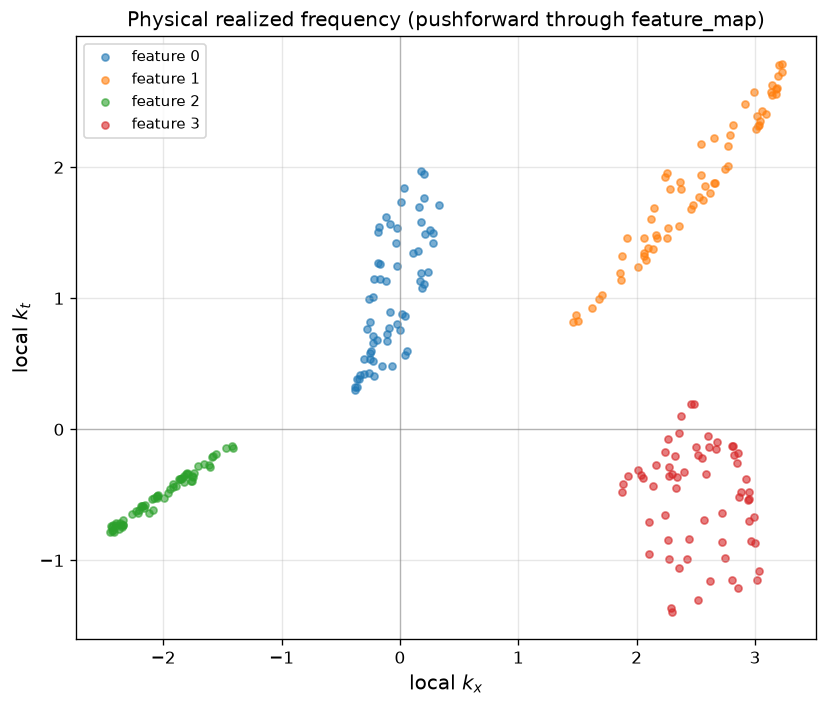

In [44]:
from src.spectral import feature_map_jacobian, physical_realized_frequency
from src.plotter import plot_physical_realized_frequency

jacobian = feature_map_jacobian(model, reference_xt)  # (B_REF, feature_size, 2)

freq_by_feature = {}
for k in range(model.feature_size):
    result = spectral_second_moment(model, reference_xt, feature_index=k)
    nonzero_freqs = {w: v for w, v in result.S.items() if w != 0}
    dominant_omega = max(nonzero_freqs, key=nonzero_freqs.get)
    print(f"feature {k}: dominant non-DC omega = {dominant_omega:+d}  (S={nonzero_freqs[dominant_omega]:.4f})")
    freq_by_feature[k] = physical_realized_frequency(jacobian, feature_index=k, omega=dominant_omega)

plot_physical_realized_frequency(
    freq_by_feature,
    save_path="figures/spectral_diagnostics/physical_realized_frequency.png",
    show=True,
)

## 8 - The only shared observables: quantum vs. classical on the physical spectrum

The classical arm has no modes, no Fock space, no `Pi_lambda` — there's no coordinate system in
which `eta_lambda` or `w_lambda` can be compared between the two arms; those quantities don't
exist on the classical side. `(x, t)` are physical coordinates with no relabeling freedom, which
is why the model's *output* spectrum on the domain grid and the per-frequency-band residual are
the only genuinely comparable observables. Builds a `match_classical_param_count` classical
counterpart (same construction as `EntanglementEntropy.ipynb` section 4) so any spectral-coverage
difference reflects architecture, not parameter budget.

quantum params: 310   classical params: 310
Parameters — total: 310  trainable: 310

Training for 1000 epochs on cpu  (dtype=torch.float32)
Epoch     1/1000 | Loss: 4.6220e+00 | PDE: 1.10e-05 | Cons: 1.30e-02 | IC: 4.60e-01 | BC: 1.99e-02 | Time: 0.0s
Epoch   100/1000 | Loss: 4.9825e+00 | PDE: 3.41e-02 | Cons: 8.58e-03 | IC: 4.92e-01 | BC: 2.31e-02 | Time: 0.2s
Epoch   200/1000 | Loss: 3.4768e+00 | PDE: 3.47e-02 | Cons: 2.33e+00 | IC: 3.08e-01 | BC: 1.27e-01 | Time: 0.3s
Epoch   300/1000 | Loss: 1.4029e+00 | PDE: 4.99e-02 | Cons: 2.46e+00 | IC: 6.74e-02 | BC: 4.33e-01 | Time: 0.5s
Epoch   400/1000 | Loss: 1.4901e+00 | PDE: 3.14e-01 | Cons: 1.96e+00 | IC: 7.09e-02 | BC: 2.71e-01 | Time: 0.6s
Epoch   500/1000 | Loss: 1.4436e+00 | PDE: 1.81e-01 | Cons: 9.85e-01 | IC: 8.54e-02 | BC: 3.10e-01 | Time: 0.8s
Epoch   600/1000 | Loss: 1.1466e+00 | PDE: 2.29e-01 | Cons: 7.33e-01 | IC: 6.00e-02 | BC: 2.44e-01 | Time: 1.0s
Epoch   700/1000 | Loss: 1.1740e+00 | PDE: 2.00e-01 | Cons: 1.28e+00 | IC: 5

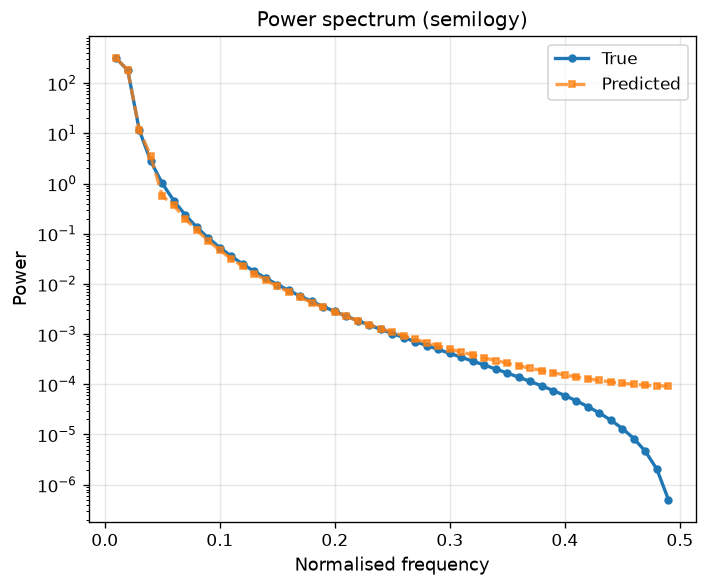

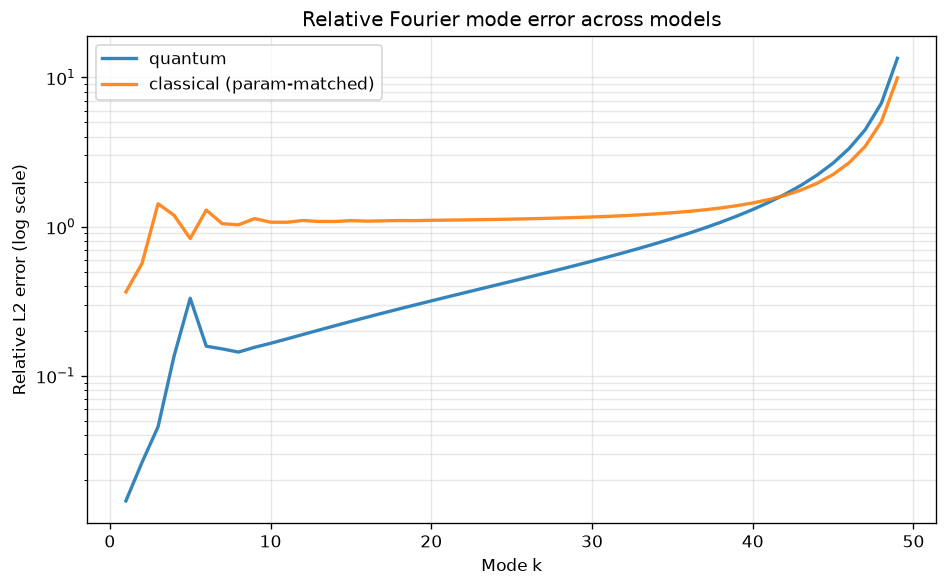

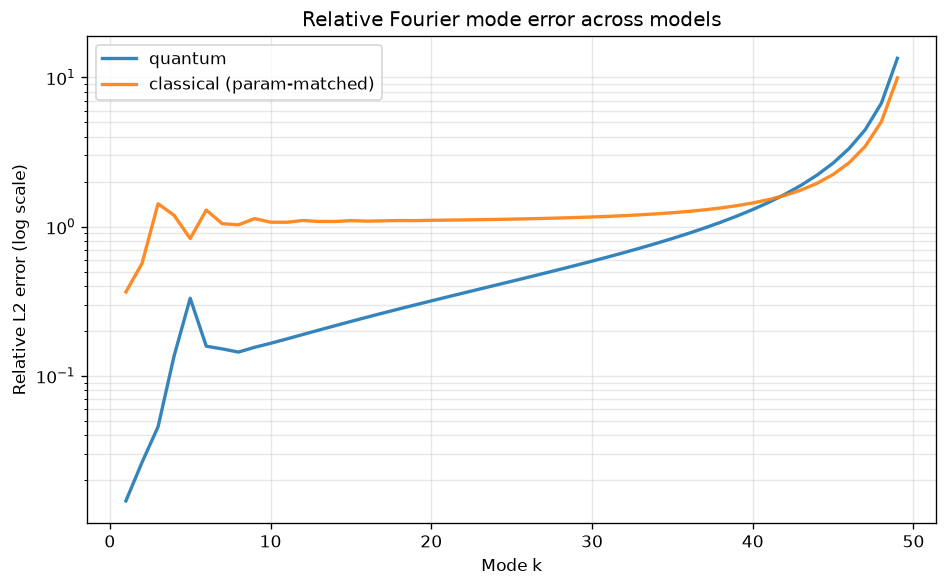

In [45]:
from src.models import match_classical_param_count
from src.eval import evaluate
from src.plotter import plot_power_spectrum, plot_multi_model_l2_error

torch.manual_seed(SEED)
classical_model = match_classical_param_count(
    model, feature_size=feature_size, n_encoding_layers=n_encoding_layers
).to(device)
q_params = sum(p.numel() for p in model.parameters())
c_params = sum(p.numel() for p in classical_model.parameters())
print(f"quantum params: {q_params}   classical params: {c_params}")

train(
    model=classical_model, pde=pde, loss_fn=total_loss,
    epochs=EPOCHS, log_every=DIAG_EVERY, seed=SEED,
    device=device, dtype=dtype,
)

metrics_q, U_pred_q, U_true, x_grid, t_grid = evaluate(
    model, pde, nx=100, nt=100, device=device, dtype=dtype, verbose=True)
metrics_c, U_pred_c, _, _, _ = evaluate(
    classical_model, pde, nx=100, nt=100, device=device, dtype=dtype, verbose=True)

plot_power_spectrum(
    U_pred_q, U_true,
    save_path="figures/spectral_diagnostics/power_spectrum_quantum.png",
    show=True,
)

plot_multi_model_l2_error(
    U_true, [U_pred_q, U_pred_c], model_names=["quantum", "classical (param-matched)"],
    save_path="figures/spectral_diagnostics/quantum_vs_classical_l2_error.png",
    show=True,
)